# Example: Value Iteration and Random Rollout in the Slippery Grid World
In this example, we return to the slippery $3\times3$ grid world of the lecture, solve it with value iteration, estimate the same values with random rollouts, and compare the two answers.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Build the slippery grid world as an MDP:__ An MDP needs the available actions of each state, the probability of each next state, and the expected reward of each action. We'll build these for the lecture's grid world and check that they reproduce the Bellman backup worked in the lecture.
> * __Solve the grid world with value iteration:__ Value iteration repeats the Bellman backup of every state until the values stop changing. We'll compute the optimal value of each square and the action the robot should take there.
> * __Estimate values with random rollouts:__ A random rollout averages the discounted rewards of simulated trajectories in which the robot picks its actions at random. We'll compare the estimates with the exact value of the random policy, and watch how the depth limit and the number of rollouts change them.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package, this example's code in [src/GridWorld.jl](src/GridWorld.jl), and the packages used here.

Let's set up our code environment:

In [1]:
# Load packages and paths -
include(joinpath(@__DIR__, "Include.jl")); # @__DIR__ locates this notebook's setup file

# Choose the plot appearance -
# After changing the theme, rerun this cell and the plotting cell.
theme(:default)   # light background
# theme(:dark)   # dark background

In addition to the Julia standard libraries, we use [DataFrames.jl](https://dataframes.juliadata.org/stable/) and [PrettyTables.jl](https://github.com/ronisbr/PrettyTables.jl) for tables and [Plots.jl](https://docs.juliaplots.org/stable/) for the figure.

### Implementation
The grid world and both algorithms live in the `L11cGridWorld` module in [src/GridWorld.jl](src/GridWorld.jl), which the setup file loads:
* [The `build_slippery_grid(...)` function](src/GridWorld.jl) builds the lecture's world: the actions available in each square, the outcomes of each action with their probabilities and rewards, the transition model $T(s^{\prime}\,|\,s,a)$, and the expected reward $R(s,a)$.
* [The `value_iteration(...)` function](src/GridWorld.jl) and [the `greedy_policy(...)` function](src/GridWorld.jl) solve the world exactly, maximizing over the available actions $\mathcal{A}_s$ of each state.
* [The `random_rollout(...)` function](src/GridWorld.jl) estimates values by simulation. It reaches the world only through [the `simulate(...)` function](src/GridWorld.jl), which returns a next state and an observed reward, so the rollouts never read $T$ or $R$. [The `random_policy_values(...)` function](src/GridWorld.jl) computes the exact value of the random policy for comparison.

#### Constants
We set the discount factor `γ`, the value iteration tolerance `ϵ` and sweep limit `k_max`, the rollout depth `d`, the rollout counts `number_of_rollouts` and `number_of_corner_rollouts`, and a `seed` for reproducible draws:

In [2]:
γ = 0.9; # discount factor, as in the lecture's grid world
ϵ = 1e-6; # value iteration tolerance
k_max = 1000; # maximum number of value iteration sweeps
d = 100; # maximum rollout depth
number_of_rollouts = 8000; # rollouts from uniformly chosen starting states
number_of_corner_rollouts = 10000; # rollouts from the corner (1,1)
seed = 5800; # reproducible random sequences

___

## Task 1: Build the slippery grid world
In this task, we build the lecture's grid world. A robot moves on a $3\times3$ grid with an obstacle at $(2,2)$ and a terminal goal at $(3,3)$. A move goes in the intended direction with probability $0.8$ and slips to each perpendicular direction with probability $0.1$. Entering the goal earns $+10$, a bump into the obstacle earns $-5$, and every other outcome earns $-1$, including a slip off the grid. A bump or a slip off the grid leaves the robot where it is, and moves off the grid are unavailable.

<style>
  .course-diagram { color-scheme: light dark; }
  :host-context(body[data-vscode-theme-kind="vscode-light"]) .course-diagram,
  :host-context(body[data-vscode-theme-kind="vscode-high-contrast-light"]) .course-diagram,
  body[data-vscode-theme-kind="vscode-light"] .course-diagram,
  body[data-vscode-theme-kind="vscode-high-contrast-light"] .course-diagram { color-scheme: light; }
  :host-context(body[data-vscode-theme-kind="vscode-dark"]) .course-diagram,
  :host-context(body[data-vscode-theme-kind="vscode-high-contrast"]) .course-diagram,
  body[data-vscode-theme-kind="vscode-dark"] .course-diagram,
  body[data-vscode-theme-kind="vscode-high-contrast"] .course-diagram { color-scheme: dark; }
  body[data-jp-theme-light="true"] .course-diagram { color-scheme: light; }
  body[data-jp-theme-light="false"] .course-diagram { color-scheme: dark; }
  @media print { .course-diagram { color-scheme: only light !important; } }
</style>
<p align="center">
    <img class="course-diagram" src="figs/Fig-GridWorld.svg" width="900" style="max-width:100%; height:auto;" alt="Two panels. Left: a three by three grid with the goal at (3,3), an obstacle at (2,2), and the reward of every other transition. Right: one intended move, which succeeds with probability zero point eight and slips to each perpendicular direction with probability zero point one."/>
</p>

We save the model in the `world::SlipperyGridWorld` variable:

In [3]:
world = L11cGridWorld.build_slippery_grid(γ = γ); # the lecture's grid world, with our discount factor

Let's list the states, their available actions $\mathcal{A}_s$, and the terminal state. The goal is absorbing: its only action is a dummy action, "stay", which keeps the robot there and earns zero reward:

In [4]:
let

    # Initialize -
    df = DataFrame();

    # One row for each state -
    for s ∈ eachindex(world.squares)
        push!(df, (state = s, square = string(world.squares[s]),
            available_actions = join(L11cGridWorld.ACTION_NAMES[world.actions[s]], ", "),
            terminal = s ∈ world.terminal));
    end

    # Display the states -
    pretty_table(df; backend = :text,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ------- -------- ------------------- ----------
  state   square   available_actions   terminal 
  Int64   String              String       Bool 
 ------- -------- ------------------- ----------
      1   (1, 1)           up, right      false
      2   (2, 1)     up, left, right      false
      3   (3, 1)            up, left      false
      4   (1, 2)     up, down, right      false
      5   (3, 2)      up, down, left      false
      6   (1, 3)         down, right      false
      7   (2, 3)   down, left, right      false
      8   (3, 3)                stay       true
 ------- -------- ------------------- ----------


### Check: Does the model reproduce the lecture's Bellman backup?
Every available action must lead to some next state, so the probabilities $T(s^{\prime}\,|\,s,a)$ of each available state-action pair must sum to one. The lecture also worked one Bellman backup by hand with $\gamma=0.9$. Starting from $U_0=0$, the first sweep gives $U_1(3,2)=7.4$, $U_1(2,1)=-1.4$, and $U_1(3,1)=-1$, and the corner's two action values are $Q_1((3,1),\mathrm{up})=4.112$ and $Q_1((3,1),\mathrm{left})=-1.432$. We build a second model with the lecture's discount factor and check these values:

In [5]:
@testset "The slippery grid world" begin

    # every available action leads to some next state -
    @test all(sum(world.T[s, :, a]) ≈ 1 for s ∈ eachindex(world.squares) for a ∈ world.actions[s])

    # the lecture's worked backup, with the lecture's discount factor -
    lecture_world = L11cGridWorld.build_slippery_grid(γ = 0.9);
    N = length(lecture_world.squares);
    U₁ = [maximum(L11cGridWorld.q_value(lecture_world, zeros(N), s, a) for a ∈ lecture_world.actions[s]) for s ∈ 1:N];
    corner = lecture_world.index[(3, 1)];
    @test U₁[lecture_world.index[(3, 2)]] ≈ 7.4 && U₁[lecture_world.index[(2, 1)]] ≈ -1.4 && U₁[corner] ≈ -1.0
    @test L11cGridWorld.q_value(lecture_world, U₁, corner, 1) ≈ 4.112 # up
    @test L11cGridWorld.q_value(lecture_world, U₁, corner, 3) ≈ -1.432 # left
end;

Test Summary:           | Pass  Total  Time
The slippery grid world |    4      4  0.6s


___

## Task 2: Solve the grid world with value iteration
In this task, we compute the optimal value $U^{*}(s)$ of each square with value iteration, and then the optimal policy $\pi^{*}(s)$, the available action with the largest expected return. We save the result of value iteration in the `solution::NamedTuple` variable and the policy in the `π_star::Vector{Int}` variable:

In [6]:
solution = L11cGridWorld.value_iteration(world, ϵ = ϵ, k_max = k_max);
π_star = L11cGridWorld.greedy_policy(world, solution.U);
println("sweeps: ", solution.iterations, ", converged: ", solution.converged)

sweeps: 21, converged: true


Let's display the optimal value and the best action of each square:

In [7]:
let

    # Initialize -
    df = DataFrame();

    # One row for each state -
    for s ∈ eachindex(world.squares)
        push!(df, (square = string(world.squares[s]), optimal_value = solution.U[s],
            best_action = L11cGridWorld.ACTION_NAMES[π_star[s]]));
    end

    # Display the values and the policy -
    pretty_table(df; backend = :text,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 -------- --------------- -------------
  square   optimal_value   best_action 
  String         Float64        String 
 -------- --------------- -------------
  (1, 1)         2.40751            up
  (2, 1)         3.93931         right
  (3, 1)         6.43088            up
  (1, 2)         3.93931            up
  (3, 2)         9.02439            up
  (1, 3)         6.43088         right
  (2, 3)         9.02439         right
  (3, 3)             0.0          stay
 -------- --------------- -------------


__What do we see?__ Values fall with distance from the goal. The two squares beside it are worth the most, and from every square the best action traces a path along the edge of the grid, around the obstacle. At $(1,1)$, up and right tie by symmetry. The tie goes to the first available action, up.

### Check: Are the values a fixed point of the Bellman backup?
Value iteration stopped because nothing moved by more than $\epsilon$. One more backup should move nothing by more than $\epsilon$ either. The best action at $(3,1)$ should also match the lecture's worked backup, which chose up:

___

## Task 3: Estimate values with random rollouts
In this task, we estimate the value of each square by simulation. A rollout starts from a random state, picks every action uniformly from $\mathcal{A}_s$, and stops at the depth limit $d$ or when the robot reaches the goal. It never reads $T$ or $R$. All it sees are the next states and rewards that `simulate(...)` hands back.

__Prediction:__ Will the rollout estimates be {close to the optimal values, well below them, or well above them}?

We save the estimates $\hat{U}(s)$ and the visit counts $n(s)$ in the `rollout::NamedTuple` variable:

In [9]:
rollout = L11cGridWorld.random_rollout(world, MersenneTwister(seed), number_of_rollouts, d);

To see what the estimates measure, we also compute the exact expected return of the random policy from the transition model: $U_d^{\mathrm{random}}(s)$ with the depth limit, and $U^{\mathrm{random}}(s)$ without it. Let's compare them with the rollout estimates and the optimal values:

In [10]:
U_random_d = L11cGridWorld.random_policy_values(world, d = d); # the random policy, stopped after d steps
U_random = L11cGridWorld.random_policy_values(world); # the random policy, without the depth limit
let

    # Initialize -
    df = DataFrame();

    # One row for each state -
    for s ∈ eachindex(world.squares)
        push!(df, (square = string(world.squares[s]), rollouts = rollout.n[s], estimate = rollout.U[s],
            random_policy_depth_d = U_random_d[s], random_policy = U_random[s], optimal_value = solution.U[s]));
    end

    # Display the comparison -
    pretty_table(df; backend = :text, display_size = (-1, -1),
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 -------- ---------- ----------- ----------------------- --------------- ---------------
  square   rollouts    estimate   random_policy_depth_d   random_policy   optimal_value 
  String      Int64     Float64                 Float64         Float64         Float64 
 -------- ---------- ----------- ----------------------- --------------- ---------------
  (1, 1)       1007    -10.5414                -10.9002        -10.9002         2.40751
  (2, 1)       1014    -10.7142                -11.0114        -11.0114         3.93931
  (3, 1)        987    -6.54453                -6.55881        -6.55881         6.43088
  (1, 2)        973    -10.8742                -11.0114        -11.0114         3.93931
  (3, 2)       1015    -1.62557                -1.25658        -1.25658         9.02439
  (1, 3)        995    -6.63745                -6.55881        -6.55881         6.43088
  (2, 3)       1015   -0.964937                -1.25658        -1.25658         9.02439
  (3, 3)        994         

__What do we see?__ The estimates track the random policy, not the optimal one. A robot choosing at random bumps the obstacle and wanders, so its expected return is negative even where the optimal value is large. The goal estimates zero: a rollout that starts there ends at once.

### Check: Do the rollouts estimate the random policy?
Each estimate should sit nearer the random policy's value than the optimal one. No policy beats the optimal, so $U^{*}(s)\geq U^{\mathrm{random}}(s)$ everywhere. The depth limit omits at most $\gamma^d r_{\max}/(1-\gamma)$, with $r_{\max}$ the largest observed reward magnitude:

### Experiment 1: Horizon Sensitivity
The lecture bounds the return that a depth limit omits by $\gamma^d r_{\max}/(1-\gamma)$. Let's compare the largest omitted return, $\max_s\lvert U^{\mathrm{random}}(s)-U_d^{\mathrm{random}}(s)\rvert$, with this bound for a few depths:

In [12]:
let

    # Initialize -
    df = DataFrame();
    r_max = maximum(abs(r) for list ∈ values(world.outcomes) for (_, _, r) ∈ list); # the largest reward magnitude

    # One row for each depth -
    for depth ∈ [1, 5, 10, 25, d]
        omitted = maximum(abs.(U_random .- L11cGridWorld.random_policy_values(world, d = depth)));
        push!(df, (depth = depth, largest_omitted_return = omitted, bound = world.γ^depth * r_max / (1 - world.γ)));
    end

    # Display the comparison -
    pretty_table(df; backend = :text,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ------- ------------------------ ------------
  depth   largest_omitted_return        bound 
  Int64                  Float64      Float64 
 ------- ------------------------ ------------
      1                  9.90023         90.0
      5                  4.67022       59.049
     10                   2.0534      34.8678
     25                 0.181577      7.17898
    100               9.87179e-7   0.00265614
 ------- ------------------------ ------------


__What do we see?__ The omitted return shrinks as depth grows, and it never exceeds the bound. The bound is loose. It charges the largest reward at every omitted step, but the rewards stop once the robot reaches the goal.

### Experiment 2: Estimator Variance
The standard error of a mean of $n$ independent returns falls as $1/\sqrt{n}$. Let's draw `number_of_corner_rollouts` returns from the corner $(1,1)$ with a second seed, then read the running mean and its standard error at a few checkpoints. We save the returns in the `corner_returns::Vector{Float64}` variable:

In [13]:
s₀ = world.index[(1, 1)]; # the starting corner
corner_returns = let
    rng = MersenneTwister(seed + 1); # a second seed for these rollouts
    [L11cGridWorld.rollout_return(world, rng, s₀, d) for _ ∈ 1:number_of_corner_rollouts];
end;

let

    # Initialize -
    df = DataFrame();
    checkpoints = [10, 100, 1000, 10000]; # numbers of rollouts to display

    # The mean and standard error after each checkpoint -
    for n ∈ checkpoints[checkpoints .≤ length(corner_returns)]
        G = view(corner_returns, 1:n);
        push!(df, (rollouts = n, running_mean = mean(G), standard_error = std(G) / sqrt(n),
            random_policy_depth_d = U_random_d[s₀]));
    end

    # Display the checkpoints -
    pretty_table(df; backend = :text, display_size = (-1, -1),
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the final mean lies within four standard errors of the exact value -
    final_error = std(corner_returns) / sqrt(length(corner_returns));
    @assert abs(mean(corner_returns) - U_random_d[s₀]) ≤ 4 * final_error
end

 ---------- -------------- ---------------- -----------------------
  rollouts   running_mean   standard_error   random_policy_depth_d 
     Int64        Float64          Float64                 Float64 
 ---------- -------------- ---------------- -----------------------
        10       -11.9402          1.58786                -10.9002
       100       -12.1046         0.662921                -10.9002
      1000        -10.839         0.228855                -10.9002
     10000       -10.8948        0.0725147                -10.9002
 ---------- -------------- ---------------- -----------------------


__What do we see?__ The standard error falls as rollouts accumulate. Once the sample is large enough to pin down the spread of the returns, every tenfold increase shrinks it by about $\sqrt{10}\approx3.2$, the $1/\sqrt{n}$ rate. The running mean settles near the random policy's value. Let's plot it with an uncertainty band:

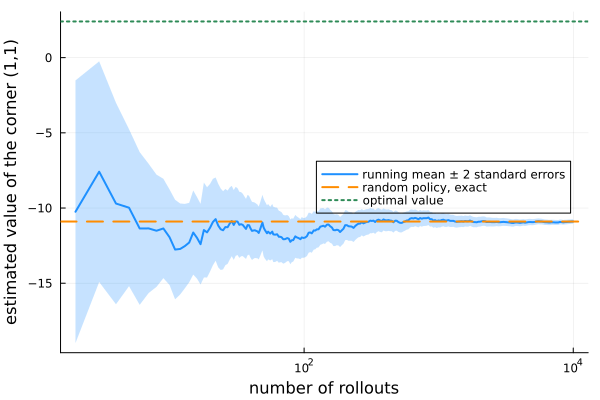

In [14]:
let

    # Initialize -
    M = length(corner_returns);
    n = unique(round.(Int, exp10.(range(log10(2), log10(M), length = 300)))); # log-spaced counts, at least two returns
    sum_G = cumsum(corner_returns);
    sum_G² = cumsum(corner_returns .^ 2);
    running_mean = sum_G[n] ./ n;
    running_se = sqrt.(max.(sum_G²[n] .- n .* running_mean .^ 2, 0.0) ./ (n .- 1)) ./ sqrt.(n);

    # Plot the running mean and the two reference values -
    p = plot(n, running_mean, ribbon = 2 .* running_se, fillalpha = 0.25, lw = 2, c = :dodgerblue,
        xscale = :log10, label = "running mean ± 2 standard errors", legend = :right,
        xlabel = "number of rollouts", ylabel = "estimated value of the corner (1,1)",
        background_color = :transparent, background_color_inside = :transparent);
    hline!(p, [U_random_d[s₀]], lw = 2, ls = :dash, c = :darkorange, label = "random policy, exact");
    hline!(p, [solution.U[s₀]], lw = 2, ls = :dot, c = :seagreen, label = "optimal value");
    p # return
end

__What do we see?__ The band narrows slowly, centred on the random policy's value and well below the corner's optimal value. More rollouts buy precision, not a better policy. The estimate converges to what random behaviour is worth.

___

## Summary
In this example, we built the lecture's slippery grid world, solved it with value iteration, and estimated its values with random rollouts.

> __Key Takeaways:__
>
> * __The grid world as an MDP:__ We encoded the available actions of each square, the probabilities of the intended move and the two slips, and the expected reward of each action. The model reproduced the Bellman backup that the lecture worked by hand.
>
> * __Value iteration finds the optimal policy:__ We repeated the Bellman backup until no value changed by more than the tolerance, then took the best action in every square. The resulting policy walks the robot along the edge of the grid to the goal, around the obstacle.
>
> * __Random rollouts estimate the random policy:__ We averaged the discounted returns of simulated random trajectories, never touching the transition model. The estimates matched the random policy's exact values, far below the optimal ones, and their standard error shrank only as one over the square root of the rollout count.

Random rollout needs only a simulator, so it works where we cannot write down the transition model. Getting near the optimal values takes more: the agent has to choose better than at random.

___